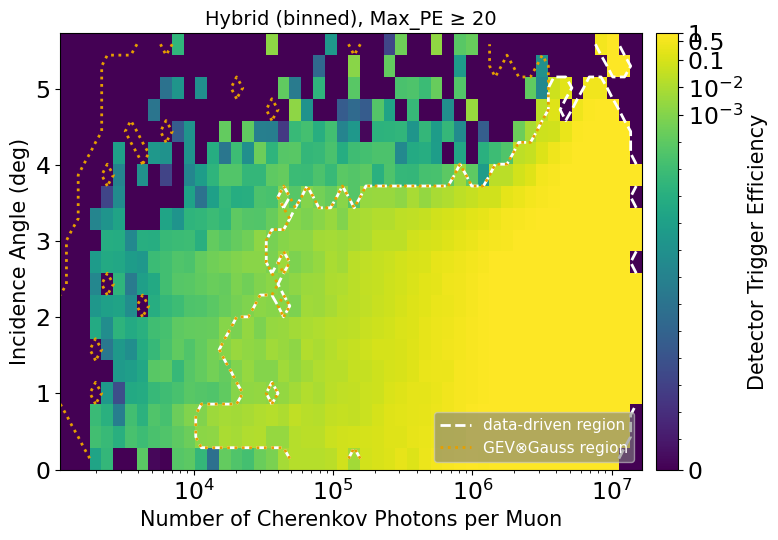

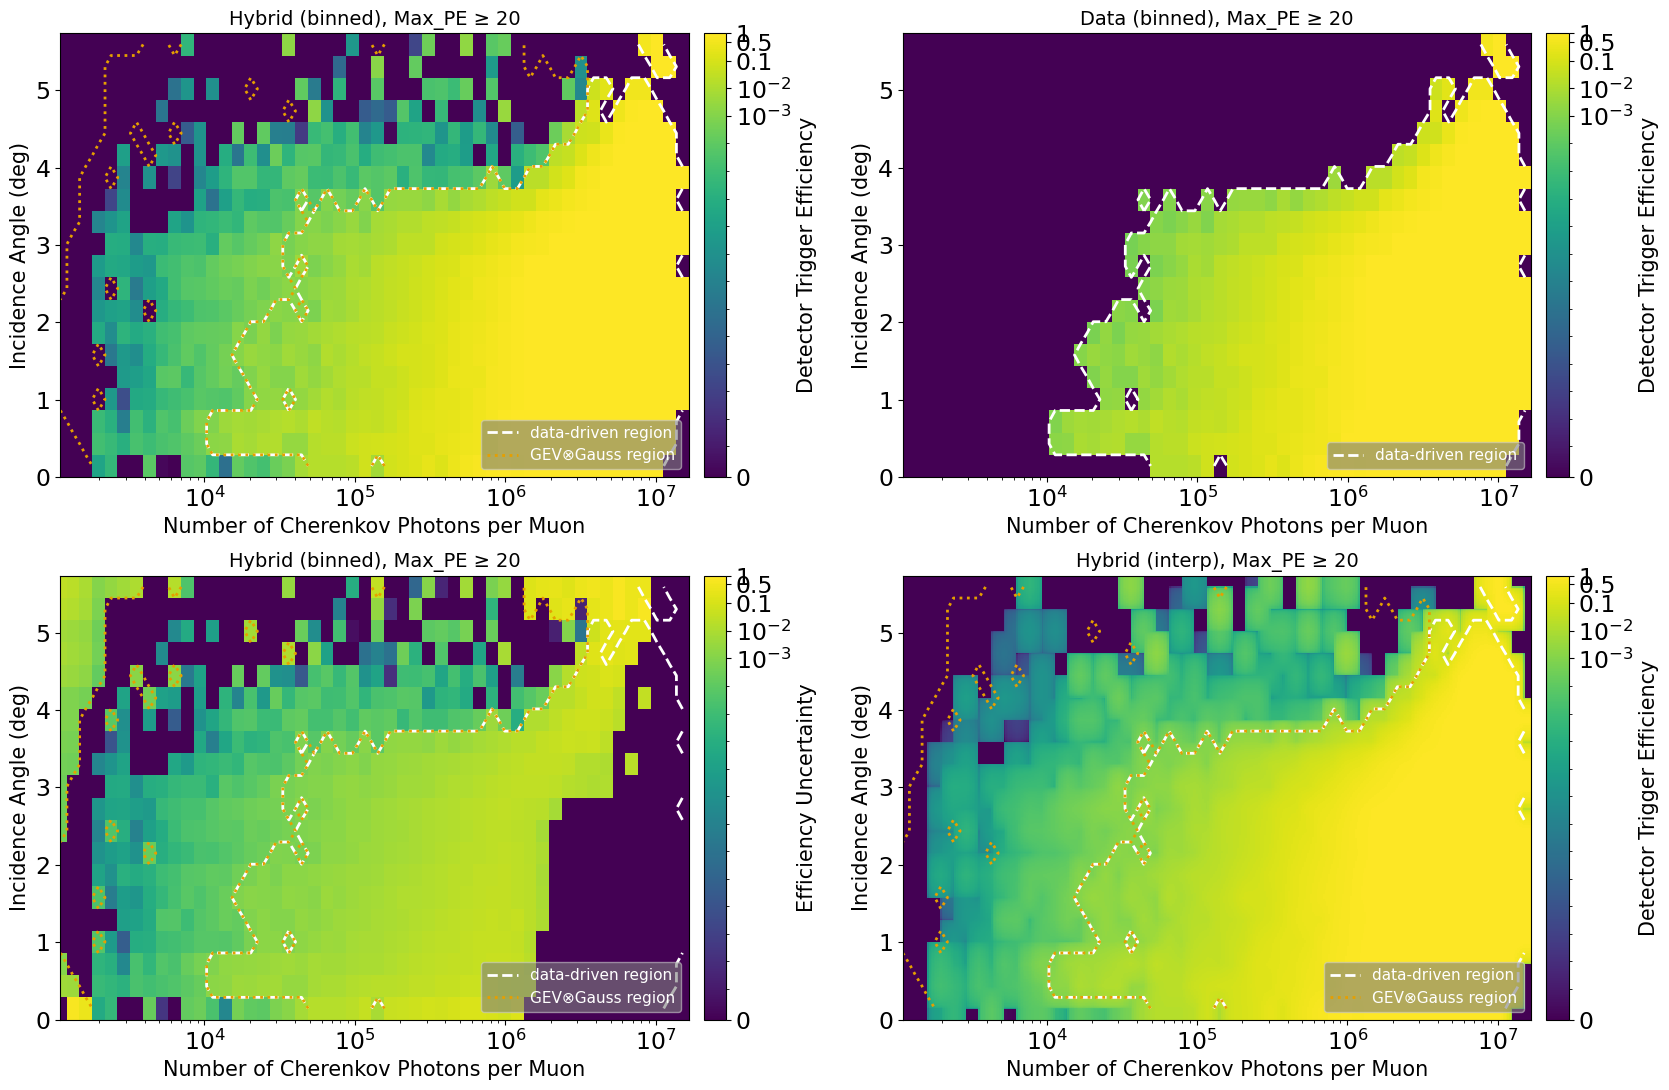

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm
from matplotlib.lines import Line2D
from trigger_eff import TriggerEfficiency

plt.rcParams.update({
    'font.family':      'sans-serif',
    'font.sans-serif':  ['DejaVu Sans'],
    'mathtext.fontset': 'dejavusans',
    'xtick.labelsize':  17,
    'ytick.labelsize':  17,
    'axes.labelsize':   15,
    'axes.titlesize':   14,
    'legend.fontsize':  11,
})

teff = TriggerEfficiency("trigger_eff_table.npz")


def plot_eff_map(teff, mode="hybrid", style="binned", show_err=False,
                 n_grid=400, linthresh=1e-15, cmap="viridis",
                 show_boundary=True, xlim=(1e3, 1e7), ax=None, savepath=None):
    """
    mode     : "hybrid" | "data"
    style    : "binned" (exact table bins) | "interp" (evaluate teff on a fine grid)
    show_err : plot the efficiency uncertainty instead of the efficiency
    """
    E, S, SRC = teff._tab[mode]
    inc_e, pc_e = teff.inc_edges, teff.pc_edges

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5.5))
    else:
        fig = ax.figure

    norm = SymLogNorm(linthresh=linthresh, vmin=0.0, vmax=1.0, base=10)

    # ── Colour layer ──────────────────────────────────────────────────────
    if style == "binned":
        Z = S if show_err else E
        pcm = ax.pcolormesh(pc_e, inc_e, Z, cmap=cmap, norm=norm,
                            shading="flat", rasterized=True)
    elif style == "interp":
        pc_g  = np.logspace(np.log10(pc_e[0]), np.log10(pc_e[-1]), n_grid)
        inc_g = np.linspace(inc_e[0], inc_e[-1], n_grid)
        I, P  = np.meshgrid(inc_g, pc_g, indexing="ij")      # (n_inc, n_pc)
        eff, err = teff(I, P, mode=mode, method="linear")
        Z = err if show_err else eff
        pcm = ax.pcolormesh(pc_g, inc_g, Z, cmap=cmap, norm=norm,
                            shading="nearest", rasterized=True)
    else:
        raise ValueError("style must be 'binned' or 'interp'")

    # ── Data-region boundary (bins with real triggers) ────────────────────
    handles = []
    if show_boundary:
        pc_c  = np.sqrt(pc_e[:-1] * pc_e[1:])
        inc_c = 0.5 * (inc_e[:-1] + inc_e[1:])
        is_data = (SRC == 1).astype(float)
        if 0 < is_data.sum() < is_data.size:
            ax.contour(pc_c, inc_c, is_data, levels=[0.5],
                       colors="white", linewidths=2, linestyles="--")
            handles.append(Line2D([], [], color="white", ls="--", lw=2,
                                  label="data-driven region"))
        if mode == "hybrid":
            is_fit = (SRC == 3).astype(float)
            if 0 < is_fit.sum() < is_fit.size:
                ax.contour(pc_c, inc_c, is_fit, levels=[0.5],
                           colors="#E69F00", linewidths=2, linestyles=":")
                handles.append(Line2D([], [], color="#E69F00", ls=":", lw=2,
                                      label="GEV⊗Gauss region"))
        if handles:
            leg = ax.legend(handles=handles, loc="lower right", framealpha=0.6,
                            facecolor="gray")
            for t in leg.get_texts():
                t.set_color("white")

    # ── Axes ──────────────────────────────────────────────────────────────
    ax.set_xscale("log")
    #ax.set_xlim(*xlim)
    ax.set_ylim(inc_e[0], inc_e[-1])
    ax.set_xlabel("Number of Cherenkov Photons per Muon")
    ax.set_ylabel("Incidence Angle (deg)")
    ax.set_title(f"{mode.capitalize()} ({style}), Max_PE ≥ {teff.pe_threshold:.0f}")

    cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
    ticks = [0, 1e-3, 1e-2, 0.1, 0.5, 1.0]
    cbar.set_ticks(ticks)
    cbar.set_ticklabels(["0", r"$10^{-3}$", r"$10^{-2}$", "0.1", "0.5", "1"])
    cbar.set_label("Efficiency Uncertainty" if show_err
                   else "Detector Trigger Efficiency")

    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight", transparent=True)
    return fig, ax


# ── Single map ────────────────────────────────────────────────────────────
fig, ax = plot_eff_map(teff, mode="hybrid", style="binned")
plt.tight_layout()
plt.show()

# ── Comparison grid: hybrid vs data, efficiency vs uncertainty ────────────
fig, axes = plt.subplots(2, 2, figsize=(17, 11))
plot_eff_map(teff, mode="hybrid", style="binned",               ax=axes[0, 0])
plot_eff_map(teff, mode="data",   style="binned",               ax=axes[0, 1])
plot_eff_map(teff, mode="hybrid", style="binned", show_err=True, ax=axes[1, 0])
plot_eff_map(teff, mode="hybrid", style="interp",               ax=axes[1, 1])
plt.tight_layout()
plt.show()

In [1]:
#Extract Data
import glob
import os
import pandas as pd
import numpy as np

# ── Settings ────────────────────────────────────────────────────────────────
TOUCH_ON_READ = True      # refresh atime/mtime of every CSV (scratch purge protection)
TOUCH_DIRS    = True      # also refresh the containing csv_output/ directories

def touch(path):
    """Equivalent of `touch path`: set atime and mtime to now. Never raises."""
    try:
        os.utime(path, None)
        return True
    except OSError as e:          # PermissionError, FileNotFoundError, ...
        print(f"WARNING: could not touch {path}: {e}")
        return False

# ── Locate all CSV files ────────────────────────────────────────────────────
#csv_dir = "/scratch/general/vast/u1520754/muon_sim_chain_tree_adaptive/data1.0/Muon_pid13_E*/csv_output"
csv_dir = "/scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E*/csv_output"

csv_files = sorted(glob.glob(os.path.join(csv_dir, "*.csv")))

print(f"Found {len(csv_files)} CSV files in {csv_dir}")
for f in csv_files:
    print(f"  {f}")

if not csv_files:
    raise SystemExit(f"No CSV files found in {csv_dir}")

# ── Load and concatenate all CSVs into one DataFrame ────────────────────────
dfs = []
n_touched = 0
for f in csv_files:
    try:
        df_i = pd.read_csv(f)
        df_i["__source_file"] = os.path.basename(f)  # keep provenance, optional
        dfs.append(df_i)
    except Exception as e:
        print(f"WARNING: failed to read {f}: {e}")
    finally:
        # touch AFTER reading, also for files that failed to parse
        if TOUCH_ON_READ:
            n_touched += touch(f)

if TOUCH_ON_READ and TOUCH_DIRS:
    for d in sorted({os.path.dirname(f) for f in csv_files}):
        touch(d)

if TOUCH_ON_READ:
    print(f"Touched {n_touched}/{len(csv_files)} CSV files")

if not dfs:
    raise SystemExit("No CSV files could be read successfully.")

df = pd.concat(dfs, ignore_index=True)
print(f"Combined DataFrame shape: {df.shape}")

# ── Helper functions ─────────────────────────────────────────────────────────
def slant_depth(zem, obs_height, zenith_rad):
    theta = np.pi - zenith_rad
    arg = (obs_height / zem) * np.sin(theta)
    arg = np.clip(arg, -1.0, 1.0)
    beta = np.where(np.isfinite(arg), np.arcsin(arg), 0.0)
    beta = np.clip(beta, 0.0, np.pi / 2)
    alpha = np.pi - theta - beta
    s = zem * np.sin(alpha) / np.sin(theta)
    return np.clip(s, 0, np.inf)

def incidence_angle(Zenith_deg, Azimuth_deg):
    cos_Zenith = np.cos(np.radians(Zenith_deg))
    cos_Azimuth = np.cos(np.radians(Azimuth_deg - 180))
    cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
    Incidence = np.degrees(np.arccos(cos_Incidence))
    return Incidence

# ── Derived columns (same as your single-file version, now on combined df) ──
X = np.array(df["tel_x"])            # m
Z = np.array(df["tel_z"])            # m
R = np.sqrt(X**2 + Z**2)             # m
H = np.array(df["height"])           # m
Zenith = np.array(df["zen"])         # deg
Azimuth = np.array(df["az"])         # deg
try:
    Inj_Zenith = np.array(df["injection_zenith_deg"])
    Inj_Azimuth = np.array(df["injection_azimuth_deg"])
    Inj_x       = np.array(df["injection_x"])
    Inj_y       = np.array(df["injection_y"])
    Inj_z       = np.array(df["injection_z_minus_R_m"])
    Inj_r       = np.sqrt(Inj_x**2 + Inj_y**2 +Inj_z**2)
    x_mag  = np.array(df["x_mag"])
    y_mag  = np.array(df["y_mag"])
    z_mag  = np.array(df["z_mag"])
    Slant  = np.sqrt((x_mag - Inj_x)**2 + (y_mag - Inj_y)**2 +(z_mag - Inj_z)**2)/1000  # km
    Inj_Incidence = incidence_angle(Inj_Zenith, Inj_Azimuth) 

except:
    Slant = slant_depth(H + 6371e3, 2944 + 6371e3, np.radians(Zenith)) / 1000  # km
    pass
Max_PE = np.array(df["max_pe"])      # photo-electron
Time_at_Max_PE = np.array(df["time_at_max_pe_ns"])  # ns
Avg_PE = np.array(df["avg_pe"])
Total_PE = np.array(df["total_pe"])
Energy_GeV = np.array(df["energy_string"])          # GeV

Ground_Energy = np.array(df["max_muon_energy_GeV"]) # GeV


cos_Zenith = np.cos(np.radians(Zenith))
cos_Azimuth = np.cos(np.radians(Azimuth - 180))
cos_Incidence = np.sqrt(1 - cos_Zenith**2 - cos_Azimuth**2)
Incidence = incidence_angle(Zenith, Azimuth)  # deg
x_corr = np.array(df["correction_x_m"])  # m
y_corr = np.array(df["correction_y_m"])  # m


r99_m = np.array(df["r99_m"])
r68_m = np.array(df["r68_m"])
seed = np.array(df["seed"])

file_size = np.array(df["file_size_MB"])  # MB
photon_count = np.array(df["cph_photon_count"])
max_photon_10ns = np.array(df["cph_max_photons_10ns"])
E_list = np.sort(np.array(list(set(Energy_GeV))))
deleted_low_pe = np.array(df["deleted_low_pe"])
runtime_hours = np.array(df["runtime_seconds"]) / 3600

total_particles    = np.array(df["total_particles"])
muon_component     = np.array(df["muon_component"])
electron_component = np.array(df["electron_component"])
hadronic_component = np.array(df["hadronic_component"])
gamma_component    = np.array(df["gamma_component"])
other_component    = np.array(df["other_component"])

# ── Summary stats ─────────────────────────────────────────────────────────
print(f"Total events: {len(df)}")
print(f"Total events with Max_PE >= 20: {np.sum(Max_PE >= 20)}")
print(f"Max_PE  -> max={np.nanmax(Max_PE):.4f}, min={np.nanmin(Max_PE):.4f}, median={np.nanmedian(Max_PE):.4f}")
print(f"Zenith  -> max={np.nanmax(Zenith):.2f}, min={np.nanmin(Zenith):.2f}, median={np.nanmedian(Zenith):.2f}")
print(f"Azimuth -> max={np.nanmax(Azimuth):.2f}, min={np.nanmin(Azimuth):.2f}, median={np.nanmedian(Azimuth):.2f}")
print(f"Production Height -> max={np.nanmax(H):.2f}, min={np.nanmin(H):.2f}, median={np.nanmedian(H):.2f}")
print(f"Unique energies found: {E_list}")

Found 172 CSV files in /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E*/csv_output
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s1.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s2.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s3.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s4.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s5.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e1_R5/csv_output/scan_care_pid13_E1.12202e1_R5_y0_s6.csv
  /scratch/general/vast/u1520754/muon_sim_chain_tree/Muon_pid13_E1.12202e2_R5/csv_output/scan_care_pid13_E1.12202e2_R5_y0_s1.cs

In [9]:
# Empirical efficiency cube on (zenith, azimuth, H, E) — OPTIMIZED version
# =============================================================================
# Key optimizations vs original:
#   1. ffill_along_H        — fully vectorized, no Python loops
#   2. efficiency_grid_H_E  — bin-membership computed once per (E,H) pair via
#                             np.digitize; tasks chunked by zenith so joblib
#                             overhead is ~N_Z_BINS jobs instead of N_tasks
#   3. _process_zen_slice   — phi/trig computed once per zenith, reused across
#                             all (H, E) bins in that slice; single batched
#                             trigger_eff_ci call per (H, E) bin
#   4. extrapolate_via_slant — same chunking strategy (one job per zen slice)
#   5. build_E_slant_pc_table — inner loop replaced with np.digitize + groupby
# =============================================================================

import os
import numpy as np
from trigger_eff import TriggerEfficiency, build_efficiency_table

# ---------- Config ----------
BOOT_SEED   = 123
N_BOOT_EFF  = 100
MIN_PTS_EFF = 5
N_E_BINS    = 10 #40
N_H_BINS    = 3 #20
N_Z_BINS    = 5 #30
N_AZ_BINS   = 5


N_JOBS      = os.cpu_count()

# ---------- Trigger-efficiency lookup ----------
FIT_NPZ = "landau_gev_gauss_2d_fit_results_weighted_tested.npz"
TABLE_NPZ = "trigger_efficiency_table.npz"  # TODO: confirm preferred output-table path.
MODE = "hybrid"       # "hybrid" or "data"
METHOD = "linear"     # "linear" or "nearest"
PE_THRESHOLD = 20.0
if not os.path.exists(TABLE_NPZ):
    build_efficiency_table(FIT_NPZ, TABLE_NPZ, n_min_trig=1,
                           pe_threshold=PE_THRESHOLD)
teff = TriggerEfficiency(TABLE_NPZ)

Telescope_Zenith = 90
ENERGY_MIN = 1e1
ENERGY_MAX = 1e5
ZEN_MIN    = np.nanmin(Zenith)
ZEN_MAX    = np.nanmax(Zenith)

AZIMUTH_RANGE = 10 #ZEN_MAX - ZEN_MIN
AZ_MIN = 0.0
AZ_MAX = AZIMUTH_RANGE  # degrees

H_MIN = np.nanmin(H) #5_000
H_MAX = np.nanmax(H) #50_000

OBS_HEIGHT_M   = 2_944.0
EARTH_RADIUS_M = 6_371_000.0

N_PARAMS   = 1
PARAM_ORDER = ["dummy"]
COV_FULL   = np.zeros((N_PARAMS, N_PARAMS))

# =============================================================================
# Helpers
# =============================================================================

def _phi_inc_grid(zen_deg, tele_zen_deg, phi_max_deg, n_phi):
    """Return phi and incidence angles for the requested azimuth samples."""
    theta_z = np.radians(zen_deg)
    psi = np.radians(tele_zen_deg)
    phi_rad = np.linspace(0.0, np.radians(phi_max_deg), n_phi)
    phi_deg = np.degrees(phi_rad)
    cos_t = (np.cos(psi) * np.cos(theta_z)
             + np.sin(psi) * np.sin(theta_z) * np.cos(phi_rad))
    theta_inc = np.degrees(np.arccos(np.clip(cos_t, -1.0, 1.0)))
    return phi_rad, phi_deg, theta_inc


def _phi_avg_eff(pc_sel, theta_inc, phi, reducer="mean",
                 n_pc_bins="fd", n_boot=100, rng=None):
    """Average vectorized lookup values across phi and return (eff, lo, hi).

    Lookup uncertainties are integrated in quadrature with trapezoid weights;
    this treats per-sample lookup errors as independent. The ``reducer``,
    ``n_pc_bins``, ``n_boot`` and ``rng`` arguments remain for call
    compatibility; sampling bootstrap is not applied in this helper.
    """
    del reducer, n_pc_bins, n_boot, rng
    pc = np.asarray(pc_sel, dtype=float)
    inc = np.asarray(theta_inc, dtype=float)
    if pc.size == 0:
        return np.nan, np.nan, np.nan
    eff, err = teff(inc[None, :], pc[:, None], mode=MODE, method=METHOD)
    mean_by_phi = np.nanmean(eff, axis=0)
    err_by_phi = np.sqrt(np.nansum(np.square(err), axis=0)) / pc.size
    if len(phi) < 2 or phi[-1] == phi[0]:
        mean = float(np.nanmean(mean_by_phi))
        sigma = float(np.sqrt(np.nanmean(np.square(err_by_phi))))
    else:
        span = phi[-1] - phi[0]
        mean = float(np.trapezoid(mean_by_phi, phi) / span)
        weights = np.empty(len(phi), dtype=float)
        weights[0] = (phi[1] - phi[0]) / 2.0
        weights[-1] = (phi[-1] - phi[-2]) / 2.0
        if len(phi) > 2:
            weights[1:-1] = (phi[2:] - phi[:-2]) / 2.0
        sigma = float(np.sqrt(np.nansum(np.square(weights * err_by_phi))) / span)
    return mean, max(0.0, mean - sigma), min(1.0, mean + sigma)


def ffill_along_H(EFF, *extras):
    """Forward-fill NaNs along H (axis 2), retaining leading NaNs."""
    n_zen, n_az, n_H, n_E = EFF.shape[:4]

    def _ffill_4d(arr):
        out = arr.copy()
        finite = np.isfinite(out)
        h_idx = np.where(finite, np.arange(n_H)[None, None, :, None], 0)
        np.maximum.accumulate(h_idx, axis=2, out=h_idx)
        z_idx = np.arange(n_zen)[:, None, None, None]
        a_idx = np.arange(n_az)[None, :, None, None]
        e_idx = np.arange(n_E)[None, None, None, :]
        out = out[z_idx, a_idx, h_idx, e_idx]
        first_finite = np.argmax(finite, axis=2)
        all_nan = ~finite.any(axis=2)
        before = np.arange(n_H)[None, None, :, None] < first_finite[:, :, None, :]
        out[before | all_nan[:, :, None, :]] = np.nan
        return out

    def _ffill_5d(arr):
        return np.stack([_ffill_4d(arr[..., p])
                         for p in range(arr.shape[4])], axis=-1)

    out_eff = _ffill_4d(EFF)
    out_extras = []
    for arr in extras:
        if arr.ndim == 4:
            out_extras.append(_ffill_4d(arr))
        elif arr.ndim == 5:
            out_extras.append(_ffill_5d(arr))
        else:
            raise ValueError(f"ffill_along_H: unsupported ndim={arr.ndim}")
    return (out_eff, *out_extras) if out_extras else out_eff


def efficiency_grid_H_E(
    E_edges, H_edges, Zen_grid, Az_grid,
    Energy_GeV, H, photon_count,
    tele_zen_deg=90.0, phi_max_deg=3.0, n_phi=50,
    min_pts=5, reducer='mean',
    n_boot=200, rng=None, n_jobs=1,
):
    """Build the existing (zenith, azimuth, H, E) products via TriggerEfficiency.

    Lookup evaluation is vectorized over each event batch and the complete
    zenith/azimuth grid. Per-bin lookup/interpolator construction is removed.
    Bin uncertainty combines lookup errors in quadrature with the standard
    error of the sampled efficiencies (also in quadrature).
    """
    del reducer, n_boot, rng, n_jobs  # retained in signature for compatibility
    E_edges = np.asarray(E_edges, dtype=float)
    H_edges = np.asarray(H_edges, dtype=float)
    Energy_GeV = np.asarray(Energy_GeV, dtype=float)
    H = np.asarray(H, dtype=float)
    photon_count = np.asarray(photon_count, dtype=float)
    Zen_grid = np.asarray(Zen_grid, dtype=float)
    Az_grid = np.asarray(Az_grid, dtype=float)

    n_zen, n_az = len(Zen_grid), len(Az_grid)
    n_H, n_E = len(H_edges) - 1, len(E_edges) - 1
    E_cen = np.sqrt(E_edges[:-1] * E_edges[1:])
    H_cen = 0.5 * (H_edges[:-1] + H_edges[1:])
    shape = (n_zen, n_az, n_H, n_E)
    EFF = np.full(shape, np.nan)
    EFF_LO = np.full(shape, np.nan)
    EFF_HI = np.full(shape, np.nan)
    COUNTS = np.zeros(shape, dtype=int)
    GRAD = np.zeros(shape + (N_PARAMS,))
    pc_in_bin = [[[None] * n_E for _ in range(n_H)] for _ in range(n_zen)]

    e_idx = np.digitize(Energy_GeV, E_edges) - 1
    h_idx = np.digitize(H, H_edges) - 1
    valid = (np.isfinite(Energy_GeV) & np.isfinite(H) & np.isfinite(photon_count)
             & (e_idx >= 0) & (e_idx < n_E)
             & (h_idx >= 0) & (h_idx < n_H))
    event_ids = np.flatnonzero(valid)
    e_valid, h_valid = e_idx[valid], h_idx[valid]
    pc_valid = photon_count[valid]

    # Preserve the original bin counts and per-bin photon-count collection.
    flat_he = h_valid * n_E + e_valid
    counts_he = np.bincount(flat_he, minlength=n_H * n_E).reshape(n_H, n_E)
    COUNTS[:] = counts_he[None, None, :, :]
    order = np.argsort(flat_he)
    sorted_flat = flat_he[order]
    sorted_pc = pc_valid[order]
    splits = np.searchsorted(sorted_flat, np.arange(n_H * n_E + 1))
    for flat in range(n_H * n_E):
        j, i = divmod(flat, n_E)
        if splits[flat + 1] - splits[flat] >= min_pts:
            values = sorted_pc[splits[flat]:splits[flat + 1]]
            for k in range(n_zen):
                pc_in_bin[k][j][i] = values

    if not len(event_ids):
        return EFF, EFF_LO, EFF_HI, COUNTS, E_cen, H_cen, pc_in_bin, GRAD

    # Compute incidence at the supplied (possibly nonuniform) azimuth points.
    phi = np.radians(Az_grid)
    psi = np.radians(tele_zen_deg)
    zrad = np.radians(Zen_grid)[:, None]
    cos_t = (np.cos(psi) * np.cos(zrad)
             + np.sin(psi) * np.sin(zrad) * np.cos(phi)[None, :])
    inc_grid = np.degrees(np.arccos(np.clip(cos_t, -1.0, 1.0)))

    sum_eff = np.zeros(shape, dtype=float)
    sum_err2 = np.zeros(shape, dtype=float)
    sum_eff2 = np.zeros(shape, dtype=float)
    n_valid_lookup = np.zeros(shape, dtype=int)
    flat_base = ((np.arange(n_zen)[:, None] * n_az
                  + np.arange(n_az)[None, :]) * n_H * n_E)
    # Chunking bounds temporary arrays while retaining vectorized table calls.
    batch_size = max(1, min(2048, 2_000_000 // max(1, n_zen * n_az)))
    for start in range(0, len(event_ids), batch_size):
        stop = min(start + batch_size, len(event_ids))
        lo, hi = event_ids[start], event_ids[stop - 1] + 1
        keep = valid[lo:hi]
        if not np.any(keep):
            continue
        e_b, h_b = e_idx[lo:hi][keep], h_idx[lo:hi][keep]
        pc_b = photon_count[lo:hi][keep]
        eff_b, err_b = teff(inc_grid[None, :, :], pc_b[:, None, None],
                            mode=MODE, method=METHOD)
        ids = (flat_base[None, :, :]
               + h_b[:, None, None] * n_E + e_b[:, None, None])
        ids = ids.ravel()
        eff_flat, err_flat = np.asarray(eff_b).ravel(), np.asarray(err_b).ravel()
        finite = np.isfinite(eff_flat) & np.isfinite(err_flat)
        sum_eff += np.bincount(ids[finite], weights=eff_flat[finite],
                               minlength=EFF.size).reshape(shape)
        sum_err2 += np.bincount(ids[finite], weights=np.square(err_flat[finite]),
                                minlength=EFF.size).reshape(shape)
        sum_eff2 += np.bincount(ids[finite], weights=np.square(eff_flat[finite]),
                                minlength=EFF.size).reshape(shape)
        n_valid_lookup += np.bincount(ids[finite], minlength=EFF.size).reshape(shape)

    # Each event contributes one valid sample per zenith/azimuth coordinate.
    counts = n_valid_lookup.astype(float)
    good = (counts >= min_pts) & (counts > 0)
    EFF[good] = sum_eff[good] / counts[good]
    model_sigma = np.zeros(shape, dtype=float)
    model_sigma[good] = np.sqrt(sum_err2[good]) / counts[good]
    stat_sigma = np.zeros(shape, dtype=float)
    multiple = good & (counts > 1)
    variance_sum = np.maximum(sum_eff2 - np.square(sum_eff) / np.maximum(counts, 1), 0.0)
    stat_sigma[multiple] = np.sqrt(variance_sum[multiple]
                                   / (counts[multiple] * (counts[multiple] - 1)))
    total_sigma = np.hypot(model_sigma, stat_sigma)
    EFF_LO[good] = np.clip(EFF[good] - total_sigma[good], 0.0, 1.0)
    EFF_HI[good] = np.clip(EFF[good] + total_sigma[good], 0.0, 1.0)
    return EFF, EFF_LO, EFF_HI, COUNTS, E_cen, H_cen, pc_in_bin, GRAD


# =============================================================================
# Driver
# =============================================================================

rng = np.random.default_rng(BOOT_SEED)
E_edges = np.logspace(np.log10(ENERGY_MIN), np.log10(ENERGY_MAX), N_E_BINS + 1)
H_edges = np.logspace(np.log10(H_MIN), np.log10(H_MAX), N_H_BINS + 1)
Zen_grid = np.linspace(ZEN_MIN, ZEN_MAX, N_Z_BINS)
Az_grid = np.linspace(AZ_MIN, AZ_MAX, N_AZ_BINS)
REDUCER = "median"  # retained for compatibility; teff has no reducer option
photon_mask = np.where((photon_count >= 0)&(R==0))
(EFF, EFF_LO, EFF_HI, COUNTS, E_cen, H_cen, pc_in_bin, GRAD) = efficiency_grid_H_E(
    E_edges, H_edges, Zen_grid, Az_grid,
    Energy_GeV[photon_mask], H[photon_mask], photon_count[photon_mask],
    tele_zen_deg=Telescope_Zenith, phi_max_deg=AZIMUTH_RANGE, n_phi=N_AZ_BINS,
    min_pts=MIN_PTS_EFF, reducer=REDUCER,
    n_boot=N_BOOT_EFF, rng=rng, n_jobs=N_JOBS,
)
filled_mask = ~np.isnan(EFF)
print(f"Filled bins: {filled_mask.sum()} / {EFF.size}  ({100*filled_mask.mean():.1f}%)")
sparse_mask = COUNTS < MIN_PTS_EFF
EFF[sparse_mask] = np.nan
EFF_LO[sparse_mask] = np.nan
EFF_HI[sparse_mask] = np.nan
EFF, EFF_LO, EFF_HI, GRAD = ffill_along_H(EFF, EFF_LO, EFF_HI, GRAD)

# Direct downstream lookup: teff(incidence_angle_deg, photon_count,
#                               mode=MODE, method=METHOD).
# TODO: replace external consumers of the removed (E, H, zenith, azimuth)
# interpolator with teff(inc, pc); those inputs cannot be mapped to pc/inc
# without the consumer's event-level variables.


Filled bins: 750 / 750  (100.0%)


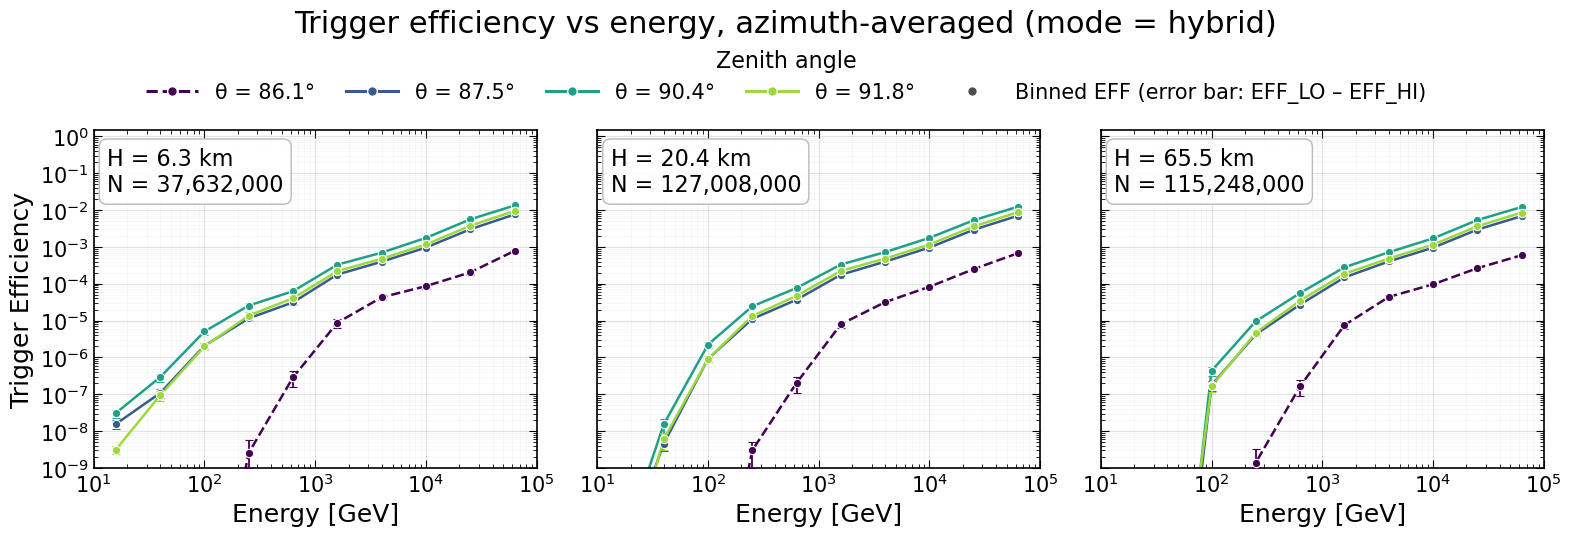

In [11]:
# Trigger efficiency vs energy per H bin (azimuth-averaged), binned points only
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogLocator, NullFormatter

# ── Style ─────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 16,
    "axes.titlesize": 18, "axes.labelsize": 18,
    "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 15, "legend.title_fontsize": 16,
    "axes.linewidth": 1.2,
    "xtick.major.size": 6, "ytick.major.size": 6,
    "xtick.minor.size": 3, "ytick.minor.size": 3,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

# ── Options ───────────────────────────────────────────────────────────────
MAX_ZEN_LINES = 4
Y_FLOOR       = 1e-9
BREAK_ON_GAPS = False   # True: leave a gap where a bin is empty/zero
                        # False: connect straight across missing bins

# ── Layout ────────────────────────────────────────────────────────────────
n_H, n_Z = len(H_cen), len(Zen_grid)
ncols = 3
nrows = int(np.ceil(n_H / ncols))

zen_inds = (np.arange(n_Z) if n_Z <= MAX_ZEN_LINES
            else np.unique(np.linspace(0, n_Z - 1, MAX_ZEN_LINES).round().astype(int)))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5.2 * nrows),
                         sharex=True, sharey=True, squeeze=False)
axes_flat = axes.ravel()
colors = plt.cm.viridis(np.linspace(0, 0.85, len(zen_inds)))

for j in range(n_H):
    ax, H_val = axes_flat[j], H_cen[j]

    for ci, k in enumerate(zen_inds):
        zen = Zen_grid[k]
        ls  = '-' if zen > 87 else '--'

        # azimuth-averaged binned efficiency and bounds
        with np.errstate(invalid="ignore"):
            eff_row = np.nanmean(EFF[k, :, j, :],    axis=0)
            lo_row  = np.nanmean(EFF_LO[k, :, j, :], axis=0)
            hi_row  = np.nanmean(EFF_HI[k, :, j, :], axis=0)
        valid = np.isfinite(eff_row) & (eff_row > 0)
        if not valid.any():
            continue

        # straight-line connection between data points
        if BREAK_ON_GAPS:
            ax.plot(E_cen, np.where(valid, eff_row, np.nan),
                    color=colors[ci], ls=ls, lw=1.8, zorder=2)
        else:
            ax.plot(E_cen[valid], eff_row[valid],
                    color=colors[ci], ls=ls, lw=1.8, zorder=2)

        # data points with asymmetric error bars
        yerr = np.vstack([
            np.clip(eff_row[valid] - np.maximum(lo_row[valid], Y_FLOOR), 0, None),
            np.clip(hi_row[valid] - eff_row[valid], 0, None),
        ])
        ax.errorbar(E_cen[valid], eff_row[valid], yerr=yerr, color=colors[ci],
                    marker='o', ms=6, mec='white', mew=0.8, ls='none',
                    elinewidth=1.3, capsize=3, zorder=3)

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(E_edges[0], E_edges[-1]); ax.set_ylim(Y_FLOOR, 1.5)
    ax.yaxis.set_major_locator(LogLocator(base=10, numticks=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10), numticks=100))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.grid(True, which='major', alpha=0.35, lw=0.8)
    ax.grid(True, which='minor', alpha=0.12, lw=0.5)

    ax.text(0.03, 0.95,
            f"H = {H_val/1e3:.1f} km\nN = {int(COUNTS[:, :, j, :].sum()):,}",
            transform=ax.transAxes, ha='left', va='top', fontsize=16,
            bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='0.7', alpha=0.9))

# Axis labels only on outer panels
for r in range(nrows):
    axes[r, 0].set_ylabel("Trigger Efficiency")
for c in range(min(ncols, n_H)):
    last = max(range(c, n_H, ncols))
    axes_flat[last].set_xlabel("Energy [GeV]")
    axes_flat[last].xaxis.set_tick_params(labelbottom=True)

for ax in axes_flat[n_H:]:
    ax.set_visible(False)

# ── Legend: zenith colours + symbol key ───────────────────────────────────
zen_handles = [Line2D([], [], color=colors[ci], lw=2.2, marker='o', ms=7, mec='white',
                      ls='-' if Zen_grid[k] > 87 else '--',
                      label=f"θ = {Zen_grid[k]:.1f}°")
               for ci, k in enumerate(zen_inds)]
key_handles = [
    Line2D([], [], color='0.3', marker='o', ms=7, mec='white', ls='none',
           label="Binned EFF (error bar: EFF_LO – EFF_HI)"),
]
fig.legend(handles=zen_handles + key_handles, loc='upper center',
           ncol=len(zen_handles) + len(key_handles),
           bbox_to_anchor=(0.5, 1.0), frameon=False, title="Zenith angle",
           handlelength=2.5, columnspacing=1.5)

fig.suptitle(f"Trigger efficiency vs energy, azimuth-averaged (mode = {MODE})",
             fontsize=22, y=1.04)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

12 12
Slope     m = -1.923441e-01 ± 1.004837e-02
Intercept b = 1.048986e+00 ± 4.991029e-02
Weighted R² = 0.97343
Effective Area (central) = 311465.6116 cm²
Effective Area (MC mean) = 3270338293.85 ± 130299148.17 cm²
Raw Area 785398.1633974483  cm²


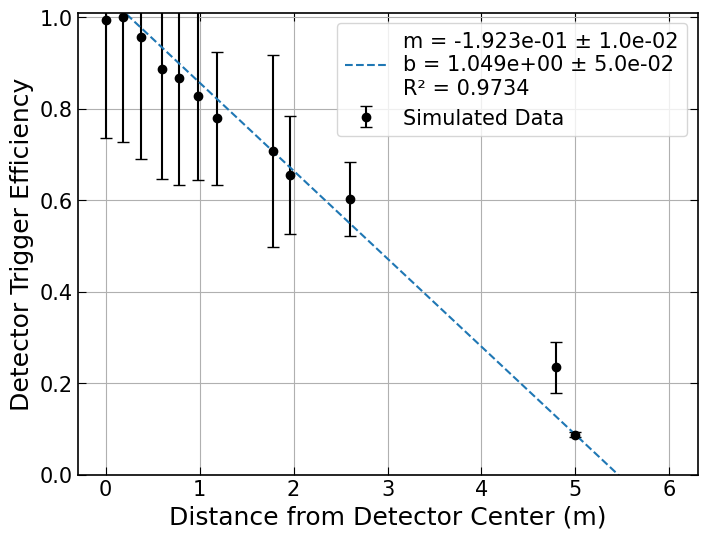

In [4]:
# Effective area from digitized trigger-rate data
# =========================================================================

# --- Digitized data ---
R_data = np.array([
    0.08165819247995529, 0.3077888370767397, 0.48994972995969954, 0.684673244738047, 
    0.9108038893348314, 1.0929647822177913, 1.2939696079438325,1.4949750087498417, 
    2.0917084625202556, 2.2738690678632314, 2.908291537479744,5.100502125323036, 
    5.301507526129045
])
R_data = R_data - R_data[1]

trigger_data = np.array([
    0.013083803640247065, 0.014237288135593221,0.014336158192090397, 0.013709980161850063, 
    0.012721279596878311, 0.012424669427386787, 0.011864406779661017, 0.011172316384180791, 
    0.010150658127951758, 0.009392655367231639, 0.008634651097874185, 0.0033615819209039553, 
    0.001252353043205994
])

trigger_rate_max = np.array([
    0.01858757062146893, 0.016016949152542374, 0.015918079096045198, 0.015160074826687743, 
    0.014138418079096047, 0.013841807909604521, 0.013775894035727291, 0.013380413809738591, 
    0.011040488636426335, 0.011139358692923509, 0.010776836158192091, 0.003855932203389831, 
    0.0018126156909317622
])
trigger_rate_err = trigger_rate_max - trigger_data

trigger_rate_err = abs(max(trigger_data)*trigger_rate_err - trigger_data*max(trigger_rate_err))/(max(trigger_data))**2 #+ 1e-10
trigger_data = trigger_data/max(trigger_data)

trigger_rate_err = trigger_rate_err[1:]
trigger_data = trigger_data[1:]
R_data = R_data[1:]
print(len(trigger_rate_err), len(trigger_data))
# --- Weighted linear fit ---
fit_weights = 1.0 / trigger_rate_err**2

(p, cov_fit) = np.polyfit(
    R_data,
    trigger_data,
    deg=1,
    w=np.sqrt(fit_weights),
    cov=True
)

m_fit, b_fit = p
m_err = np.sqrt(cov_fit[0, 0])
b_err = np.sqrt(cov_fit[1, 1])

print(f"Slope     m = {m_fit:.6e} ± {m_err:.6e}")
print(f"Intercept b = {b_fit:.6e} ± {b_err:.6e}")

# --- Weighted R² ---
y_fit        = m_fit * R_data + b_fit
weighted_mean = np.average(trigger_data, weights=fit_weights)
ss_res = np.sum(fit_weights * (trigger_data - y_fit)**2)
ss_tot = np.sum(fit_weights * (trigger_data - weighted_mean)**2)
r_squared = 1 - ss_res / ss_tot
print(f"Weighted R² = {r_squared:.5f}")

# --- Central effective area ---
r_grid = np.linspace(0, 6, 10000)
trigger_rate_r      = np.clip(m_fit * r_grid + b_fit, 0, None)
trigger_rate_r_norm = trigger_rate_r / trigger_rate_r.max()
effective_area_central = 2 * np.pi * np.trapezoid(
    trigger_rate_r_norm * r_grid, x=r_grid
)
print(f"Effective Area (central) = {effective_area_central * 1e4:.4f} cm²")

# --- Monte Carlo uncertainty propagation ---
N_mc = 1000
samples = np.random.multivariate_normal(
    mean=[m_fit, b_fit],
    cov=cov_fit,
    size=N_mc
)

area_samples = []
for m_i, b_i in samples:
    trigger_i = np.clip(m_i * r_grid + b_i, 0, None)
    if trigger_i.max() <= 0:
        continue
    trigger_i_norm = trigger_i 
    area_i = 2 * np.pi * np.trapezoid(trigger_i_norm * r_grid, x=r_grid)
    area_samples.append(area_i)

area_samples = np.array(area_samples) * 1e4 #convert to cm^2

effective_area_mean = np.mean(area_samples) 
effective_area_std  = np.std(area_samples) 
raw_area = np.pi*500**2

print(f"Effective Area (MC mean) = {effective_area_mean * 1e4:.2f} ± "
      f"{effective_area_std * 1e4:.2f} cm²")
print("Raw Area", raw_area, " cm²")
# --- Fit plot ---
plt.figure(figsize=(8, 6))
plt.errorbar(R_data, trigger_data, yerr=trigger_rate_err,
             fmt='o', color="black", capsize=4, label='Simulated Data')
plt.plot(r_grid, (m_fit * r_grid + b_fit), '--',
         label=(
                f'm = {m_fit:.3e} ± {m_err:.1e}\n'
                f'b = {b_fit:.3e} ± {b_err:.1e}\n'
                f'R² = {r_squared:.4f}'))


plt.xlabel("Distance from Detector Center (m)")
plt.ylim(0,1.01)
plt.ylabel("Detector Trigger Efficiency")
plt.grid(True)
plt.legend()
#plt.savefig("/uufs/chpc.utah.edu/common/home/u1520754/Muon_Trinity/plot/eff_r.png",transparent=True)

plt.show()

In [5]:
# Muon Flux Calculation
import pickle
import numpy as np
import matplotlib.pyplot as plt

def convert_altitude_to_depth(altitude_m, zenith_deg):
    altitude_m  = np.asarray(altitude_m, dtype=float)
    altitude_km = altitude_m * 1e-3
    altitude_cm = altitude_m * 100.0

    zenith_deg  = np.asarray(zenith_deg, dtype=float)
    zenith_deg  = np.where(zenith_deg >= 90.0, 89.9, zenith_deg)

    depth = np.empty_like(altitude_m)

    m1 = (altitude_km >   0.0) & (altitude_km <   4.0)
    m2 = (altitude_km >=  4.0) & (altitude_km <  10.0)
    m3 = (altitude_km >= 10.0) & (altitude_km <  40.0)
    m4 = (altitude_km >= 40.0) & (altitude_km <= 100.0)
    m5 =  altitude_km > 100.0

    depth[m1] = -186.555305 + 1222.6562 * np.exp(-altitude_cm[m1] / 994186.38)
    depth[m2] =  -94.919    + 1144.9069 * np.exp(-altitude_cm[m2] / 878153.55)
    depth[m3] =    0.61289  + 1305.5948 * np.exp(-altitude_cm[m3] / 636143.04)
    depth[m4] =    0.0      +  540.1778 * np.exp(-altitude_cm[m4] / 772170.16)
    depth[m5] =    0.01128292 - altitude_cm[m5] / 1e9

    depth /= np.cos(np.deg2rad(zenith_deg))

    return depth


def eff_sigma_func_X(E_mesh, H_mesh, Z_mesh, A_mesh):
    X_mesh = convert_altitude_to_depth(H_mesh, Z_mesh)
    return eff_sigma_func(E_mesh, H_mesh, Z_mesh, A_mesh)

# =========================================================================
# 2. Load the precomputed MCEq grid
# =========================================================================
"""with open('/uufs/chpc.utah.edu/common/home/u1520754/Muon_Trinity/data/'
          'mceq_grid_80_90deg_Nzen100_no_decay_no_E_loss.pkl', 'rb') as f:"""
with open('/uufs/chpc.utah.edu/common/home/u1520754/Muon_Trinity/data/'
          'mceq_grid_0_90deg_Nzen100_no_decay_no_E_loss.pkl', 'rb') as f:          
    grid_data = pickle.load(f)

zen_centers_all = grid_data['zen_centers']
cos_edges       = grid_data['cos_edges']
sin_edges       = np.sqrt(1-cos_edges**2)
theta_edges     = np.arccos(cos_edges)
int_sin2_edges  = (theta_edges - sin_edges*cos_edges)/2
E_GeV           = grid_data['E_GeV']

min_E           = ENERGY_MIN #grid_data['min_E'] #
max_E           = 1e6#grid_data['max_E'] #
E_mask          = (E_GeV>=min_E)&(E_GeV<=max_E)
E_GeV           = E_GeV[E_mask]

zen_min_use, zen_max_use = 0, 90.0
tele_azimuth = 270
n_azimuth = 5

zen_mask = (zen_centers_all >= zen_min_use) & (zen_centers_all <= zen_max_use)
if not np.any(zen_mask):
    raise ValueError(
        f"No zenith bins in [{zen_min_use}, {zen_max_use}] deg. "
        f"Available centers: {zen_centers_all}"
    )

zen_centers = zen_centers_all[zen_mask]

min_az, max_az = tele_azimuth - AZIMUTH_RANGE, tele_azimuth + AZIMUTH_RANGE
phi = np.linspace(0, AZIMUTH_RANGE, n_azimuth)

dphi = np.radians(max_az - min_az)

selected_entries = [e for e, keep in zip(grid_data['per_zenith'], zen_mask) if keep]

# Azimuth offsets (same for every zenith). 
# phi already defined above as: phi = np.linspace(0, AZIMUTH_RANGE, n_azimuth)
n_A = len(phi)

flux_slices = []   # will hold one (n_H, n_E) -> (n_H, n_E, n_A) array per zenith
zen_list    = []   # keep track of the zenith value for each slice (for bookkeeping)
X_list      = []
for entry in selected_entries:
    theta  = entry['theta']      # zenith (deg) for this slice
    H_grid = entry['H_grid']     # emission heights (cm)
    d_CDF  = entry['d_CDF']      # muon flux, shape (n_H, n_E)  <-- adjust if different
    X_grid = entry['X_grid']
    # --- the flux for this zenith: shape (n_H, n_E) ---
    d_X = np.gradient(X_grid)[:,None]
    #d_CDF = d_CDF/d_X
    flux_HE = np.asarray(d_CDF)[:, E_mask]

    # --- broadcast over azimuth: (n_H, n_E) -> (n_H, n_E, n_A) ---
    flux_HEA = np.broadcast_to(flux_HE[:, :, None], flux_HE.shape + (n_A,))

    flux_slices.append(flux_HEA)
    zen_list.append(theta)
    X_list.append(X_grid)
X_arr = np.array(X_list)
# Stack along a new leading zenith axis -> (Z, H, E, A)
flux_tensor = np.stack(flux_slices, axis=0)

zen_arr = np.array(zen_list)   # (Z,)

print("flux_tensor shape (Z, H, E, A):", flux_tensor.shape)
print("zenith values:", zen_arr)

# Common axes (built once)
H_m      = np.asarray(selected_entries[0]['H_grid']) / 100.0   # (n_H,)
E_axis   = np.asarray(E_GeV)                                   # (n_E,)
phi_axis = np.asarray(phi)                                     # (n_A,)

# 3D meshes for ONE zenith slice — built once, reused every iteration
H_mesh, E_mesh, A_mesh = np.meshgrid(H_m, E_axis, phi_axis, indexing='ij')
# each shape (n_H, n_E, n_A) ≈ 18 MB

Z_mesh = np.empty_like(H_mesh)   # reused buffer for the scalar zenith

eff_slices = []
eff_slices_lo = []
eff_slices_hi = []
for theta in zen_arr:
    print(theta)
    Z_mesh.fill(theta)                                   # constant zenith
    #eff_HEA = eff_func(E_mesh, H_mesh, Z_mesh, A_mesh)   # (n_H, n_E, n_A)
    eff_HEA, eff_lo, eff_hi = eff_sigma_func(E_mesh, H_mesh, Z_mesh, A_mesh)
    eff_slices.append(eff_HEA.astype(np.float32))        # downcast to save RAM if neccesary
    eff_slices_lo.append(eff_lo.astype(np.float32))        # downcast to save RAM if neccesary
    eff_slices_hi.append(eff_hi.astype(np.float32))        # downcast to save RAM if neccesary

eff_tensor = np.stack(eff_slices, axis=0)   # (Z, H, E, A)
eff_tensor_lo = np.stack(eff_slices_lo, axis=0)
eff_tensor_hi = np.stack(eff_slices_hi, axis=0)
print("eff_tensor shape:", eff_tensor.shape, "dtype:", eff_tensor.dtype)
assert eff_tensor.shape == flux_tensor.shape

flux_eff_tensor = eff_tensor*flux_tensor
flux_eff_tensor_lo = eff_tensor_lo*flux_tensor
flux_eff_tensor_hi = eff_tensor_hi*flux_tensor
# =========================================================================
# Extrapolate flux grid to 91.8 degrees by copying the 90-degree slice
# =========================================================================

# Find the index of the 90-degree zenith slice
idx_90 = np.argmin(np.abs(zen_arr - 90.0))
print(f"Using zenith slice at {zen_arr[idx_90]:.2f}° as the basis for extrapolation")

# Define the new zenith angles to extrapolate to (above 90 degrees)
zen_extrap = np.degrees(np.arccos(np.linspace(np.cos(np.radians(91.8)), np.cos(np.radians(90)), 10))) #np.array([91.8, 91.0, 90.9])  # can add more values here if needed

# --- Flux extrapolation ---
# Copy the 90° flux slice for each new zenith angle
flux_extrap_slices = []
X_extrap = []
for z_new in zen_extrap:
    # Copy the 90° slice: shape (H, E, A)
    flux_extrap_slices.append(flux_tensor[idx_90].copy())
    X_extrap.append(X_arr[idx_90].copy())
flux_extrap_tensor = np.stack(flux_extrap_slices, axis=0)  # (Z_new, H, E, A)
print(f"flux_extrap_tensor shape: {flux_extrap_tensor.shape}")
# --- Efficiency extrapolation ---
# Recompute efficiency at the new zenith angles
eff_extrap_slices    = []
eff_extrap_slices_lo = []
eff_extrap_slices_hi = []

for z_new in zen_extrap:
    print(f"Computing efficiency at zenith = {z_new}°")
    Z_mesh_extrap = np.full_like(H_mesh, z_new)
    eff_HEA, eff_lo, eff_hi = eff_sigma_func(E_mesh, H_mesh, Z_mesh_extrap, A_mesh)
    eff_extrap_slices.append(eff_HEA.astype(np.float32))
    eff_extrap_slices_lo.append(eff_lo.astype(np.float32))
    eff_extrap_slices_hi.append(eff_hi.astype(np.float32))

eff_extrap_tensor    = np.stack(eff_extrap_slices,    axis=0)  # (Z_new, H, E, A)
eff_extrap_tensor_lo = np.stack(eff_extrap_slices_lo, axis=0)
eff_extrap_tensor_hi = np.stack(eff_extrap_slices_hi, axis=0)
print(f"eff_extrap_tensor shape: {eff_extrap_tensor.shape}")

# --- Concatenate original + extrapolated tensors ---
zen_arr_full          = np.concatenate([zen_extrap, zen_arr         ])
X_arr_full            = np.concatenate([np.array(X_extrap),   X_arr])
flux_tensor_full      = np.concatenate([flux_extrap_tensor, flux_tensor],      axis=0)
eff_tensor_full       = np.concatenate([eff_extrap_tensor, eff_tensor       ],       axis=0)
eff_tensor_lo_full    = np.concatenate([eff_extrap_tensor_lo, eff_tensor_lo    ],    axis=0)
eff_tensor_hi_full    = np.concatenate([eff_extrap_tensor_hi, eff_tensor_hi    ],    axis=0)

flux_eff_tensor_full    = eff_tensor_full    * flux_tensor_full
flux_eff_tensor_lo_full = eff_tensor_lo_full * flux_tensor_full
flux_eff_tensor_hi_full = eff_tensor_hi_full * flux_tensor_full

print(f"\nFinal combined tensor shapes:")
print(f"  zen_arr_full:          {zen_arr_full}")
print(f"  flux_tensor_full:      {flux_tensor_full.shape}")
print(f"  eff_tensor_full:       {eff_tensor_full.shape}")
print(f"  flux_eff_tensor_full:  {flux_eff_tensor_full.shape}")


# Replace the original tensors with the full ones for downstream use
zen_arr          = zen_arr_full
X_arr            = X_arr_full
flux_tensor      = flux_tensor_full
eff_tensor       = eff_tensor_full
eff_tensor_lo    = eff_tensor_lo_full
eff_tensor_hi    = eff_tensor_hi_full
flux_eff_tensor    = flux_eff_tensor_full
flux_eff_tensor_lo = flux_eff_tensor_lo_full
flux_eff_tensor_hi = flux_eff_tensor_hi_full

print("\nDone. Downstream variables updated to include 91.8° extrapolation.")


flux_tensor shape (Z, H, E, A): (100, 1000, 40, 5)
zenith values: [89.71351991 89.14053108 88.56745626 87.99423807 87.42081895 86.8471412
 86.27314686 85.6987777  85.12397513 84.54868019 83.97283344 83.39637495
 82.81924422 82.24138011 81.66272081 81.08320375 80.50276553 79.92134189
 79.3388676  78.75527641 78.17050095 77.5844727  76.99712184 76.40837723
 75.81816627 75.22641485 74.6330472  74.03798584 73.44115141 72.84246263
 72.24183609 71.63918621 71.03442501 70.42746206 69.81820423 69.20655562
 68.5924173  67.97568716 67.35625974 66.73402594 66.10887286 65.48068352
 64.84933659 64.21470612 63.57666123 62.93506577 62.28977795 61.64064997
 60.98752759 60.33024966 59.66864764 59.00254501 58.33175675 57.65608859
 56.97533637 56.28928522 55.59770869 54.9003678  54.19700999 53.4873679
 52.77115812 52.04807971 51.31781255 50.58001553 49.83432453 49.08035005
 48.31767461 47.5458498  46.76439285 45.97278279 45.17045595 44.35680084
 43.53115217 42.69278389 41.84090107 40.97463023 40.09300799

Empty (zero/NaN) computed cells: 5922 of 100000
10 extrapolated zenith rows (> 89.714°), mode = loglinear


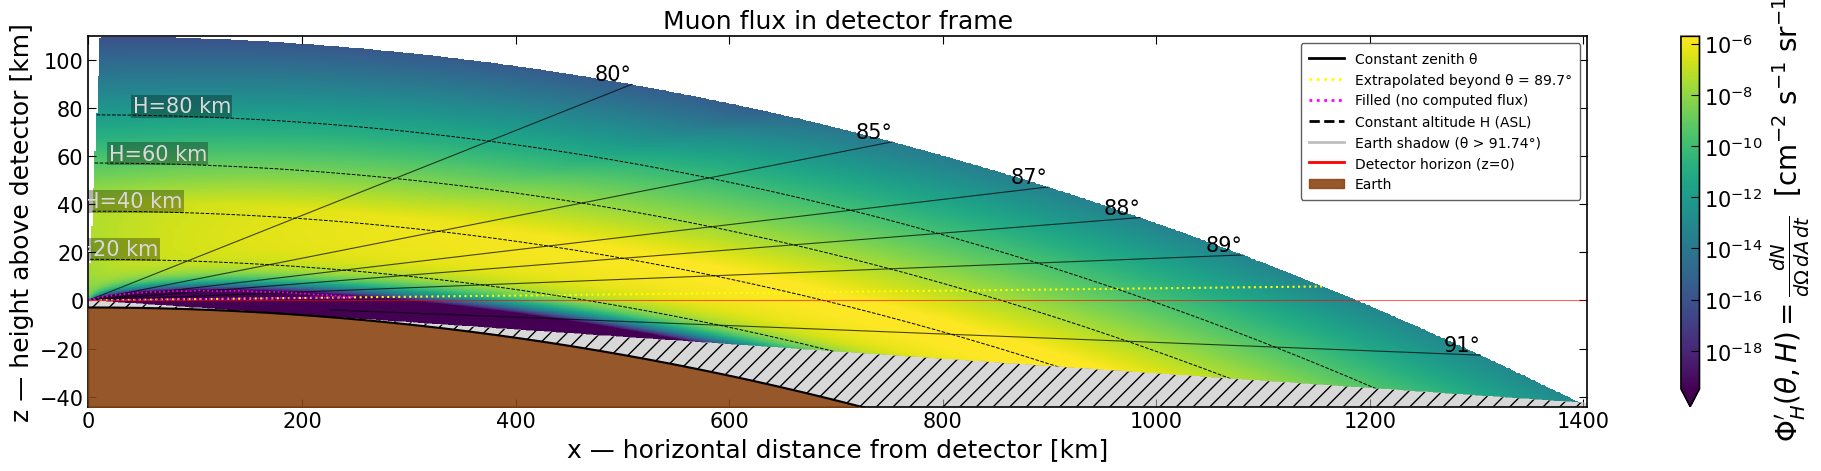

In [16]:
# Muon flux map: detector-centred Cartesian x (horizontal) vs z (vertical)
# =========================================================================
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.interpolate import RegularGridInterpolator

# ------------------------- user options ----------------------------------
FLUX_SOURCE   = "raw"      # "raw" -> flux_tensor, "eff" -> flux_eff_tensor
GEOMETRY      = "curved"   # "curved" (spherical Earth) or "flat"
E_INTEGRATE   = "trapz"    # "trapz" if d_CDF is dN/dE ; "sum" if per-E-bin
R_EARTH       = 6371e3     # m
H_OBS         = 2944.0     # m, detector altitude
H_IS_ASL      = True       # True: H_grid is above sea level; False: above detector
H_CONTOURS_KM = [20, 40, 60, 80]          # constant-altitude guide curves (ASL, km)
ZEN_RAYS_DEG  = [80, 85, 87, 88, 89, 91]  # zenith rays to draw (degrees)
SHOW_EARTH    = True
EARTH_COLOR   = "saddlebrown"
EARTH_ALPHA   = 0.9
EARTH_EDGE    = "black"
N_PIX         = 900        # image resolution (pixels per axis)
ZEN_MASK_TOL  = 1e-3       # deg

# Extrapolation beyond the last computed zenith
EXTRAP_MODE   = "loglinear"   # "copy" or "loglinear"
N_FIT         = 4             # last computed zenith rows used for the slope

# Filling of empty (zero / NaN) cells and of altitudes below the grid
FILL_MODE     = "loglinear"   # "loglinear" or "nearest"
N_FIT_H       = 4             # finite H cells used for the slope
FLOOR_DECADES = 2.0           # floor = VMIN / 10**FLOOR_DECADES
N_PAD_H       = 30            # padded altitude nodes below the grid
H_GROUND      = 0.0           # m ASL, lowest altitude to fill to
SHOW_SHADOW   = True          # shade region hidden behind the Earth limb
SHOW_FILLED   = True          # outline cells that are filled, not computed

# Last zenith actually computed (from the ORIGINAL grid, before extrapolation)
ZEN_MAX_REAL  = float(zen_centers.max())  # ~89.714 deg
# -------------------------------------------------------------------------

_trapz = getattr(np, "trapezoid", None) or np.trapz
F = flux_eff_tensor if FLUX_SOURCE == "eff" else flux_tensor

# --- integrate over E -> (Z, H, A), average azimuth -> (Z, H) ---
F_ZHA = _trapz(F, x=E_axis, axis=2) if E_INTEGRATE == "trapz" else F.sum(axis=2)
F_ZH  = F_ZHA.mean(axis=-1)

# --- sort by zenith, drop duplicated slices ---
order        = np.argsort(zen_arr)
zen_sorted   = np.asarray(zen_arr)[order]
F_sorted     = F_ZH[order]
zen_u, idx_u = np.unique(np.round(zen_sorted, 6), return_index=True)
F_u          = F_sorted[idx_u]                          # (Z_u, n_H)

# --- absolute altitude, sorted ascending ---
H_alt = np.asarray(H_m if H_IS_ASL else H_m + H_OBS, dtype=float)
h_ord = np.argsort(H_alt)
H_alt = H_alt[h_ord]
F_u   = F_u[:, h_ord]
H_MIN_REAL, H_MAX_REAL = H_alt[0], H_alt[-1]

# --- work in log10 space ---
with np.errstate(divide="ignore", invalid="ignore"):
    logF = np.where(np.isfinite(F_u) & (F_u > 0), np.log10(F_u), np.nan)

ext_rows = zen_u > ZEN_MAX_REAL + ZEN_MASK_TOL
comp_idx = np.where(~ext_rows)[0]

# Colour limits from computed, finite data only
_finite = logF[comp_idx][np.isfinite(logF[comp_idx])]
VMIN, VMAX = 10**np.percentile(_finite, 1), 10**_finite.max()
LOG_FLOOR  = np.log10(VMIN) - FLOOR_DECADES

# Mask of cells that are NOT genuinely computed
filled = ~np.isfinite(logF)
filled[ext_rows] = True
print(f"Empty (zero/NaN) computed cells: {np.sum(~np.isfinite(logF[comp_idx]))} "
      f"of {logF[comp_idx].size}")

# =========================================================================
# 1) Fill empty cells inside the grid (along H, then along zenith)
# =========================================================================
def _slope(xv, yv):
    return np.polyfit(xv, yv, 1)[0] if (FILL_MODE == "loglinear" and xv.size >= 2) else 0.0

def fill_rows(L, H, rows):
    ar = np.arange(L.shape[1])
    for k in rows:
        y  = L[k]
        ok = np.isfinite(y)
        if ok.all() or not ok.any():
            continue
        idx = np.where(ok)[0]
        inner = (~ok) & (ar > idx[0]) & (ar < idx[-1])
        if inner.any():
            y[inner] = np.interp(H[inner], H[ok], y[ok])
        lo = ar < idx[0]
        if lo.any():
            f = idx[:N_FIT_H]
            y[lo] = y[idx[0]] + _slope(H[f], y[f]) * (H[lo] - H[idx[0]])
        hi = ar > idx[-1]
        if hi.any():
            f = idx[-N_FIT_H:]
            y[hi] = y[idx[-1]] + _slope(H[f], y[f]) * (H[hi] - H[idx[-1]])
        new = ~ok
        y[new] = np.maximum(y[new], LOG_FLOOR)
    return L

logF = fill_rows(logF, H_alt, comp_idx)

# rows that were completely empty: fill along zenith
for h in range(logF.shape[1]):
    col = logF[comp_idx, h]
    ok  = np.isfinite(col)
    if ok.sum() >= 2 and not ok.all():
        col[~ok] = np.interp(zen_u[comp_idx][~ok], zen_u[comp_idx][ok], col[ok])
        logF[comp_idx, h] = col

# =========================================================================
# 2) Zenith extrapolation (beyond ZEN_MAX_REAL)
# =========================================================================
if EXTRAP_MODE == "loglinear" and ext_rows.any():
    fit_rows = comp_idx[-N_FIT:]
    k_last   = comp_idx[-1]
    for h in range(logF.shape[1]):
        y  = logF[fit_rows, h]
        ok = np.isfinite(y)
        slope = np.polyfit(zen_u[fit_rows][ok], y[ok], 1)[0] if ok.sum() >= 2 else 0.0
        logF[ext_rows, h] = np.maximum(
            logF[k_last, h] + slope * (zen_u[ext_rows] - zen_u[k_last]), LOG_FLOOR)
else:
    logF = fill_rows(logF, H_alt, np.where(ext_rows)[0])   # "copy": just close holes
print(f"{ext_rows.sum()} extrapolated zenith rows (> {ZEN_MAX_REAL:.3f}°), "
      f"mode = {EXTRAP_MODE}")

# =========================================================================
# 3) Altitude padding (below the lowest computed H, down to the ground)
# =========================================================================
if H_alt[0] > H_GROUND:
    H_pad = np.linspace(H_GROUND, H_alt[0], N_PAD_H + 1)[:-1]
    pad   = np.full((logF.shape[0], H_pad.size), np.nan)
    for k in range(logF.shape[0]):
        f = np.arange(min(N_FIT_H, logF.shape[1]))
        pad[k] = np.maximum(logF[k, 0] + _slope(H_alt[f], logF[k, f]) * (H_pad - H_alt[0]),
                            LOG_FLOOR)
    logF   = np.hstack([pad, logF])
    filled = np.hstack([np.ones_like(pad, dtype=bool), filled])
    H_alt  = np.concatenate([H_pad, H_alt])

logF = np.where(np.isfinite(logF), logF, LOG_FLOOR)       # safety net

# =========================================================================
# Geometry
# =========================================================================
R0 = R_EARTH + H_OBS

def detector_xz(zen_deg, H_abs):
    """Forward map (θ, H) -> (x, z) in metres, origin at detector."""
    th = np.radians(np.asarray(zen_deg))[:, None]
    Hh = np.asarray(H_abs)[None, :]
    if GEOMETRY == "flat":
        dz = Hh - H_OBS
        with np.errstate(divide="ignore", invalid="ignore"):
            x = dz * np.tan(th)
        ok = (np.degrees(th) < 90.0) & (dz > 0)
        z = np.broadcast_to(dz, x.shape)
        return np.where(ok, x, np.nan), np.where(ok, z, np.nan)
    RH = R_EARTH + Hh
    disc = (R0 * np.cos(th))**2 + RH**2 - R0**2
    s = -R0 * np.cos(th) + np.sqrt(np.where(disc >= 0, disc, np.nan))
    ok = (RH > R0) & np.isfinite(s)
    return np.where(ok, s * np.sin(th), np.nan), np.where(ok, s * np.cos(th), np.nan)

def detector_inverse(x, z):
    """Inverse map (x, z) [m] -> (θ [deg], H ASL [m])."""
    zen = np.degrees(np.arctan2(x, z))
    H = H_OBS + z if GEOMETRY == "flat" else np.hypot(x, R0 + z) - R_EARTH
    return zen, H

# --- plot extent from the computed altitude range ---
x_ext, z_ext = detector_xz(zen_u, np.linspace(H_MIN_REAL, H_MAX_REAL, 200))
xmax    = np.nanmax(x_ext) / 1e3
zmin_ax = np.nanmin(z_ext) / 1e3
zmax_ax = np.nanmax(z_ext) / 1e3

# =========================================================================
# Image: interpolate in the native (θ, H) grid
# =========================================================================
xg = np.linspace(0.0, xmax, N_PIX)
zg = np.linspace(zmin_ax, zmax_ax, N_PIX)
Xg, Zg = np.meshgrid(xg, zg)
zen_g, H_g = detector_inverse(Xg * 1e3, Zg * 1e3)
pts = np.column_stack([zen_g.ravel(), H_g.ravel()])

interp = RegularGridInterpolator((zen_u, H_alt), logF, method="linear",
                                 bounds_error=False, fill_value=np.nan)
logF_img = interp(pts).reshape(Xg.shape)

interp_f = RegularGridInterpolator((zen_u, H_alt), filled.astype(float),
                                   method="linear", bounds_error=False, fill_value=0.0)
filled_img = interp_f(pts).reshape(Xg.shape)

# --- Earth shadow: lines of sight beyond the limb are blocked ---
theta_graze = (180.0 - np.degrees(np.arcsin(R_EARTH / R0))) if GEOMETRY == "curved" else 90.0
above_ground = H_g > H_GROUND
shadow = (zen_g > theta_graze) & above_ground
outside = shadow | ~above_ground | (H_g > H_MAX_REAL) | ~np.isfinite(logF_img)
F_img = np.ma.masked_where(outside, 10**np.nan_to_num(logF_img, nan=LOG_FLOOR))

# =========================================================================
# Plot
# =========================================================================
fig, ax = plt.subplots(figsize=(20, 5))

norm = LogNorm(vmin=VMIN, vmax=VMAX)
pcm = ax.pcolormesh(Xg, Zg, F_img, norm=norm, cmap="viridis",
                    shading="auto", rasterized=True)

H_line = np.linspace(min(H_GROUND, H_MIN_REAL), H_MAX_REAL, 600)

# Constant-zenith rays
for i, zz in enumerate(ZEN_RAYS_DEG):
    xr, zr = detector_xz(np.array([zz], float), H_line)
    xr, zr = xr[0] / 1e3, zr[0] / 1e3
    ok = np.isfinite(xr) & np.isfinite(zr)
    if not ok.any():
        print(f"Note: θ={zz}° does not cross the plotted region")
        continue
    ax.plot(xr[ok], zr[ok], color="black", lw=0.8, alpha=0.7,
            label="Constant zenith θ" if i == 0 else None)
    t = np.argmax(np.hypot(xr[ok], zr[ok]))
    ax.text(xr[ok][t], zr[ok][t], f"{zz:.0f}°", color="black", fontsize=15,
            ha="right", va="bottom", clip_on=True)

# Boundary of the extrapolated zenith region
if ext_rows.any():
    xe, ze = detector_xz(np.array([ZEN_MAX_REAL]), H_line)
    ax.plot(xe[0] / 1e3, ze[0] / 1e3, ":", color="yellow", lw=1.5,
            label=f"Extrapolated beyond θ = {ZEN_MAX_REAL:.1f}°")

# Outline of filled (non-computed) cells, excluding the zenith extrapolation
if SHOW_FILLED:
    fill_only = np.where((zen_g <= ZEN_MAX_REAL) & ~outside, filled_img, 0.0)
    if (fill_only > 0.5).any():
        ax.contour(Xg, Zg, fill_only, levels=[0.5], colors="magenta",
                   linewidths=1.2, linestyles=":")
        ax.plot([], [], ":", color="magenta", lw=1.2,
                label="Filled (no computed flux)")

# Constant-altitude curves
zen_fine = np.linspace(zen_u.min(), min(zen_u.max(), theta_graze), 400)
first_H = True
for Hk in H_CONTOURS_KM:
    xc, zc = detector_xz(zen_fine, np.array([Hk * 1e3]))
    xc, zc = xc[:, 0] / 1e3, zc[:, 0] / 1e3
    inside = (np.isfinite(xc) & np.isfinite(zc)
              & (xc >= 0) & (xc <= xmax) & (zc >= zmin_ax) & (zc <= zmax_ax))
    if not inside.any():
        continue
    xc, zc = xc[inside], zc[inside]
    ax.plot(xc, zc, "--", color="black", lw=0.7, clip_on=True,
            label="Constant altitude H (ASL)" if first_H else None)
    first_H = False
    m = len(xc) // 2
    ax.text(xc[m], zc[m], f"H={Hk} km", color="0.85", fontsize=15,
            ha="center", va="bottom", clip_on=True,
            bbox=dict(facecolor="black", alpha=0.3, lw=0, pad=1))

# Earth shadow
if SHOW_SHADOW and shadow.any():
    ax.contourf(Xg, Zg, shadow.astype(float), levels=[0.5, 1.5],
                colors=["0.75"], alpha=0.6, hatches=["//"], zorder=2)
    ax.plot([], [], color="0.75", lw=6, alpha=0.6,
            label=f"Earth shadow (θ > {theta_graze:.2f}°)")

ax.axhline(0, color="red", lw=0.8, alpha=0.6, label="Detector horizon (z=0)")

# Earth surface
if SHOW_EARTH:
    x_s = np.linspace(0.0, xmax, 1000)
    if GEOMETRY == "flat":
        z_surf = np.full_like(x_s, -H_OBS / 1e3)
    else:
        Rk, zc0 = R_EARTH / 1e3, -R0 / 1e3
        z_surf = zc0 + np.sqrt(np.maximum(Rk**2 - x_s**2, 0.0))
    ax.fill_between(x_s, zmin_ax, z_surf, where=(z_surf > zmin_ax),
                    color=EARTH_COLOR, alpha=EARTH_ALPHA, zorder=3, label="Earth")
    ax.plot(x_s, z_surf, color=EARTH_EDGE, lw=1.5, zorder=4)

cb = fig.colorbar(pcm, ax=ax, extend="min")
label = "Triggered muon flux" if FLUX_SOURCE == "eff" else "Muon flux"
cb.set_label(r"$\Phi_H' (\theta, H) = \frac{dN}{d\Omega\, dA\, dt}$  [cm$^{-2}$ s$^{-1}$ sr$^{-1}$]",
             fontsize=20)

ax.set_xlabel("x — horizontal distance from detector [km]")
ax.set_ylabel("z — height above detector [km]")
ax.set_title(f"{label} in detector frame")
ax.set_xlim(0, xmax)
ax.set_ylim(zmin_ax, zmax_ax)

leg = ax.legend(loc="upper right", fontsize=10, frameon=True,
                facecolor="white", edgecolor="0.3", framealpha=0.9,
                handlelength=2.5, borderpad=0.6)
for line in leg.get_lines():
    line.set_linewidth(2.0)
    line.set_alpha(1.0)

plt.tight_layout()
plt.show()

In [16]:
def Muon_Rate_Calculation(flux_eff_tensor, effective_area_mean, E_axis, phi_axis,zen_arr):    
    R_zen_az = np.sum(np.trapezoid(flux_eff_tensor, x = E_axis, axis = 2), axis = 1)*effective_area_mean
    R_zen = 2*np.trapezoid(R_zen_az*np.cos(np.radians(phi_axis)), x = np.radians(phi_axis), axis = 1)

    zen_arr = zen_arr-Telescope_Zenith
    zen_arr_pos = zen_arr[zen_arr >=0]
    R_zen_pos = R_zen[zen_arr >=0]
    R_pos = np.trapezoid(R_zen_pos*np.cos(np.radians(zen_arr_pos))**2, x = -(np.radians(zen_arr_pos)), axis = 0) * 3600 *24

    zen_arr_neg = zen_arr[zen_arr < 0]
    R_zen_neg = R_zen[zen_arr < 0]
    R_neg = np.trapezoid(R_zen_neg*np.cos(np.radians(zen_arr_neg))**2, x = -(np.radians(zen_arr_neg)), axis = 0) * 3600 *24

    R = R_neg + R_pos
    return R, R_neg, R_pos


Rate = Muon_Rate_Calculation(flux_eff_tensor, effective_area_mean , E_axis, phi_axis, zen_arr)[0]  #effective_area_mean
Rate_raw = Muon_Rate_Calculation(flux_tensor_full, raw_area, E_axis, phi_axis, zen_arr)[0]
Rate_lo = Muon_Rate_Calculation(flux_eff_tensor_lo, effective_area_mean - effective_area_std, E_axis, phi_axis, zen_arr)[0]
Rate_hi = Muon_Rate_Calculation(flux_eff_tensor_hi, effective_area_mean + effective_area_std, E_axis, phi_axis, zen_arr)[0]
print("Raw rate", Rate_raw)
print(Rate/3, Rate_lo/3, Rate_hi/3, "muons per 8 hours")

Raw rate 19924055.708322722
0.04824624526623376 0.039882629033723284 0.05713530562314112 muons per 8 hours


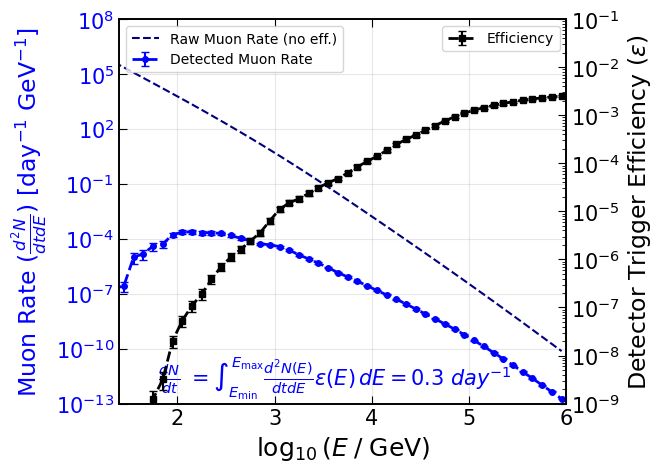

In [17]:
def Muon_Rate_per_E_Calculation(flux_eff_tensor, effective_area_mean, phi_axis,zen_arr):    
    R_zen_az_E = np.sum(flux_eff_tensor, axis = 1)
    R_zen_E = 2*np.trapezoid(R_zen_az_E*np.cos(np.radians(phi_axis)), x = np.radians(phi_axis), axis = 2)
    zen_arr = zen_arr-Telescope_Zenith
    zen_arr_pos = zen_arr[zen_arr >=0][:, None]
    R_zen_pos = R_zen_E[zen_arr >=0]
    R_pos = np.trapezoid(R_zen_pos*np.cos(np.radians(zen_arr_pos))**2, x = -(np.radians(zen_arr_pos)), axis = 0) * 3600 *24

    zen_arr_neg = zen_arr[zen_arr < 0][:, None]
    R_zen_neg = R_zen_E[zen_arr < 0]
    R_neg = np.trapezoid(R_zen_neg*np.cos(np.radians(zen_arr_neg))**2, x = -(np.radians(zen_arr_neg)), axis = 0) * 3600 *24

    R_E = R_neg + R_pos
    return R_E*effective_area_mean
"""def Muon_Rate_per_E_Calculation(flux_eff_tensor, effective_area_mean, phi_axis, zen_arr, X_arr):
    # flux_eff_tensor: (Z, H, E, A)
    # X_arr:           (Z, H)
    n_Z, n_H, n_E, n_A = flux_eff_tensor.shape

    # Integrate over H using X as variable, per zenith slice -> (Z, E, A)
    R_ZEA = np.empty((n_Z, n_E, n_A))
    for iz in range(n_Z):
        X_slice     = X_arr[iz]           # (n_H,)
        flux_slice  = flux_eff_tensor[iz] # (n_H, n_E, n_A)

        sort_idx    = np.argsort(X_slice)
        X_sorted    = X_slice[sort_idx]
        flux_sorted = flux_slice[sort_idx]

        R_ZEA[iz]   = np.trapezoid(flux_sorted, x=X_sorted, axis=0)  # (n_E, n_A)

    # Integrate over azimuth with cos(phi) weighting: (Z, E, A) -> (Z, E)
    R_zen_E = 2 * np.trapezoid(
        R_ZEA * np.cos(np.radians(phi_axis)),
        x=np.radians(phi_axis),
        axis=2
    )

    # Zenith offset from telescope pointing
    zen_offset = zen_arr - Telescope_Zenith   # (Z,)

    zen_pos    = zen_offset[zen_offset >= 0][:, None]   # (Z+, 1)
    R_zen_pos  = R_zen_E[zen_offset >= 0]               # (Z+, E)
    R_pos      = np.trapezoid(
        R_zen_pos * np.cos(np.radians(zen_pos))**2,
        x=-np.radians(zen_pos),
        axis=0
    ) * 3600 * 24                                       # (E,)

    zen_neg    = zen_offset[zen_offset < 0][:, None]    # (Z-, 1)
    R_zen_neg  = R_zen_E[zen_offset < 0]                # (Z-, E)
    R_neg      = np.trapezoid(
        R_zen_neg * np.cos(np.radians(zen_neg))**2,
        x=-np.radians(zen_neg),
        axis=0
    ) * 3600 * 24                                       # (E,)

    R_E = (R_pos + R_neg) * effective_area_mean
    return R_E


R_E     = Muon_Rate_per_E_Calculation(flux_eff_tensor,    effective_area_mean,                  phi_axis, zen_arr, X_arr)
R_E_lo  = Muon_Rate_per_E_Calculation(flux_eff_tensor_lo, effective_area_mean - effective_area_std, phi_axis, zen_arr, X_arr)
R_E_hi  = Muon_Rate_per_E_Calculation(flux_eff_tensor_hi, effective_area_mean + effective_area_std, phi_axis, zen_arr, X_arr)
R_E_raw = Muon_Rate_per_E_Calculation(flux_tensor,        raw_area,                             phi_axis, zen_arr, X_arr)
R_eff   = R_E / R_E_raw"""


R_E = Muon_Rate_per_E_Calculation(flux_eff_tensor, effective_area_mean, phi_axis, zen_arr)
R_E_lo = Muon_Rate_per_E_Calculation(flux_eff_tensor_lo, effective_area_mean - effective_area_std, phi_axis, zen_arr)
R_E_hi = Muon_Rate_per_E_Calculation(flux_eff_tensor_hi, effective_area_mean + effective_area_std, phi_axis, zen_arr)
R_E_raw = Muon_Rate_per_E_Calculation(flux_tensor, raw_area, phi_axis, zen_arr)
R_eff = R_E/R_E_raw

fig, ax1 = plt.subplots(figsize=(7, 5))

# ── left axis : muon rate ──────────────────────────────────────────────────
color_rate = 'blue'

err_lo = R_E - R_E_lo  # lower error bar lengths (always positive)
err_lo = np.clip(err_lo, np.min(err_lo[err_lo>0]), None)
err_hi = R_E_hi - R_E   # upper error bar lengths (always positive)
E_data_mask = E_axis<= max(Energy_GeV)
ax1.errorbar(
    np.log10(E_axis[E_data_mask]), R_E[E_data_mask],
    yerr=[err_lo[E_data_mask], err_hi[E_data_mask]],
    fmt='--o',
    color=color_rate,
    ecolor=color_rate,
    elinewidth=1.5,
    capsize=3,
    markersize=4,
    linewidth=2,
    label='Detected Muon Rate',
)
#ax1.plot(np.log10(E_axis), R_E, color=color_rate, linewidth=1.5, linestyle='--', label='Extrapolate Muon Rate')
ax1.plot(np.log10(E_axis), R_E_raw,
         color='navy', linewidth=1.5, linestyle='--', label='Raw Muon Rate (no eff.)')

ax1.set_yscale('log')
ax1.set_xlabel(r'$\log_{10}(E\;/\;\mathrm{GeV})$')
ax1.set_ylabel(r'Muon Rate $(\frac{d^{2}N}{dtdE})$ [day$^{-1}$ GeV$^{-1}$]', color=color_rate, fontsize=17)
ax1.tick_params(axis='y', labelcolor=color_rate)
ax1.legend(loc='upper left', fontsize=10)

# ── right axis : efficiency ────────────────────────────────────────────────
color_eff = 'black'
ax2 = ax1.twinx()

# Efficiency error bars propagated from lo/hi rate ratios
R_eff_lo = R_E_lo / R_E_raw
R_eff_hi = R_E_hi / R_E_raw

eff_err_lo = R_eff - R_eff_lo
eff_err_lo = np.clip(eff_err_lo, np.min(eff_err_lo[eff_err_lo>0]), None)

eff_err_hi = R_eff_hi - R_eff

#ax2.plot(np.log10(E_axis), R_eff, color=color_eff, linewidth=1.5, linestyle='--', label='Raw Muon Rate (no eff.)')

ax2.errorbar(
    np.log10(E_axis[E_data_mask]), R_eff[E_data_mask],
    yerr=[eff_err_lo[E_data_mask], eff_err_hi[E_data_mask]],
    fmt='--s',
    color=color_eff,
    ecolor=color_eff,
    elinewidth=1.5,
    capsize=3,
    markersize=4,
    linewidth=2,
    label='Efficiency',
)

ax2.set_ylabel(r'Detector Trigger Efficiency $(\epsilon)$', color=color_eff, fontsize=17)
ax2.tick_params(axis='y', labelcolor=color_eff)
ax2.set_yscale("log")
ax2.legend(loc='upper right', fontsize=10)

# ── cosmetics ─────────────────────────────────────────────────────────────
ax1.grid(True, which='both', alpha=0.3)
ax1.text(1.8, 1e-12, 
        r"$\frac{dN}{dt}\ = \int_{E_{\min}}^{E_{\max}} \frac{d^{2}N(E)}{dtdE} \epsilon(E) \, dE = 0.3$"+" "+r"$ day^{-1}$",
        fontsize=15,
        color = color_rate
)
fig.tight_layout()
ax1.set_ylim(1e-13, 1e8)
ax2.set_ylim(1e-9, 1e-1)
plt.xlim(1.4, 6)
plt.show()
